# Part 5: Học máy (Phân chia dữ liệu, Học có giám sát, Học không giám sát)
**Thành viên phụ trách:** Thành viên 5 | **Nhánh Git:** `feature/ml-insight-analysis` | **Mã nguồn:** `modeling/train.py`, `modeling/unsupervised.py`

---
Notebook chạy và **đánh giá** toàn bộ phần học máy của dự án FlightRisk VN. Mọi con số được tính trực tiếp từ dữ liệu và mô hình ở lần chạy này, không nhập tay.

| Phần | Nội dung | Điều được kiểm chứng |
| :-: | :--- | :--- |
| 1 | Chia Train/Test **theo thời gian** (do Thành viên 4 tạo) | Train kết thúc trước Test; X không chứa cột rò rỉ; lệch phân phối theo thời gian |
| 2 | Phân loại 3 lớp, hồi quy số phút trễ, tầm quan trọng đặc trưng | Mô hình có **hơn baseline** không; chọn mô hình **không dùng Test**; xác suất có đáng tin không |
| 3 | K-Means, PCA, Isolation Forest, luật kết hợp | Tên cụm **suy ra từ dữ liệu**; k có hợp lý không; cụm ổn định giữa Train và Test; chuyến bị gắn cờ khác bình thường ở đâu |
| 4 | Tổng kết và hạn chế | Kết luận tự động kèm cảnh báo |

**Cách chạy:** cần `data/processed/train.csv`, `test.csv` và các artifact của Thành viên 4 (chạy `python main.py encode`). Notebook **ghi đè** các tệp trong `models/`. Thời gian chạy vài phút.

> **Về cách chọn mô hình:** mô hình được chọn bằng `TimeSeriesSplit` **trên Train** (huấn luyện trên quá khứ, chấm trên giai đoạn kế tiếp), rồi mới đánh giá trên Test **một lần**. Chọn mô hình theo điểm Test sẽ làm điểm Test lạc quan hơn thực tế.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import auc as sk_auc, precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if not (ROOT / "config.py").exists() and (ROOT.parent / "config.py").exists():
    ROOT = ROOT.parent                      # notebook đặt trong notebooks/
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from modeling import train as tr
from modeling import unsupervised as un
from modeling.encoding import LABEL_MAP, LEAKAGE_COLUMNS, PROCESSED_DIR, split_by_date

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
CLASS_NAMES = tr.CLASS_NAMES
print(f"Thư mục dự án: {ROOT} | scikit-learn {sklearn.__version__}")
assert tr.FILE_TRAIN.exists() and tr.FILE_TEST.exists(), "Thiếu train.csv/test.csv. Nhờ Thành viên 4 chạy: python main.py encode"

Thư mục dự án: c:\Users\LENOVO\Documents\ScrapeData | scikit-learn 1.9.1


## 1. Chia dữ liệu theo thời gian (chống Lookahead Bias)
Dữ liệu chuyến bay là chuỗi thời gian: nếu xáo trộn ngẫu nhiên, mô hình "học lỏm" thời tiết và tải sân bay của **ngày tương lai** để dự báo quá khứ. Vì vậy: sắp xếp theo `(flight_date, scheduled_time)`, 80% đầu làm Train, 20% sau làm Test; bộ tiền xử lý chỉ fit trên Train (do Thành viên 4 thực hiện, `train.py` chỉ **đọc** kết quả).

Train: 11,172 chuyến | Test: 2,793 chuyến | số đặc trưng X: 64 | mốc cắt: 2026-10-31
ĐẠT: X không chứa cột rò rỉ, nhãn đích hay delay_min.


,Train,Test,Số chuyến Train,Số chuyến Test
on_time,69.1,80.0,7725,2235
delayed,29.8,19.9,3330,556
cancelled,1.0,0.1,117,2


Chênh lệch tỷ lệ trễ giữa Train và Test: 9.9 điểm phần trăm  -> LỆCH PHÂN PHỐI THEO THỜI GIAN, cần nêu trong báo cáo.
Số chuyến hủy trong Test: 2 -> các chỉ số của lớp cancelled có độ bất định rất lớn.

Đối chiếu với flights_features.csv: Train 11,172 / Test 2,793 -> KHỚP với train.csv/test.csv
ĐẠT: ngày cuối Train (2026-10-31) <= ngày đầu Test (2026-10-31).


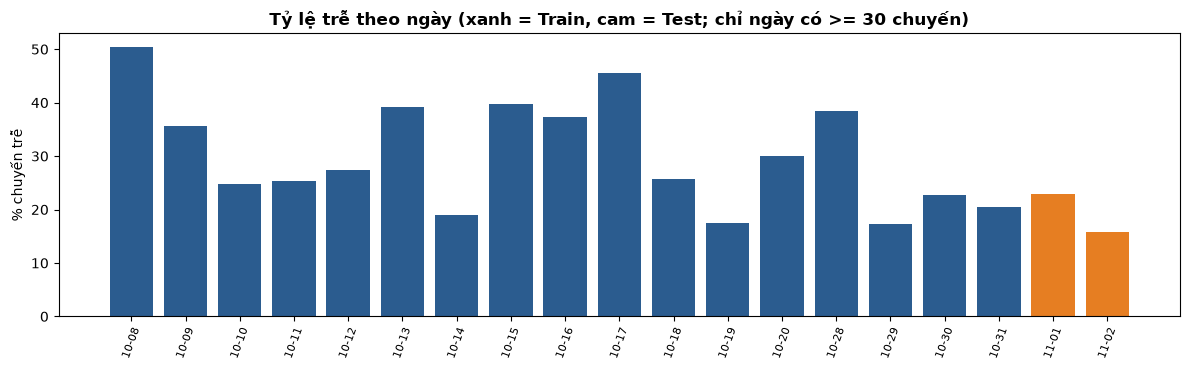

In [2]:
X_train, X_test, y_train, y_test, delay_train, delay_test = tr.load_train_test_data()
meta = json.loads(tr.FILE_METADATA.read_text(encoding="utf-8")) if tr.FILE_METADATA.exists() else {}
print(f"Train: {len(X_train):,} chuyến | Test: {len(X_test):,} chuyến | số đặc trưng X: {X_train.shape[1]} | mốc cắt: {meta.get('cutoff_date')}")

for c in list(LEAKAGE_COLUMNS) + ["target", "status_clean", "delay_min"]:
    assert c not in X_train.columns, f"Rò rỉ: {c} nằm trong X"
print("ĐẠT: X không chứa cột rò rỉ, nhãn đích hay delay_min.")

share = pd.DataFrame({
    "Train": [(y_train == v).mean() * 100 for v in LABEL_MAP.values()],
    "Test": [(y_test == v).mean() * 100 for v in LABEL_MAP.values()],
    "Số chuyến Train": [(y_train == v).sum() for v in LABEL_MAP.values()],
    "Số chuyến Test": [(y_test == v).sum() for v in LABEL_MAP.values()],
}, index=list(LABEL_MAP)).round(1)
display(share)
drift = abs(share.loc["delayed", "Train"] - share.loc["delayed", "Test"])
print(f"Chênh lệch tỷ lệ trễ giữa Train và Test: {drift:.1f} điểm phần trăm" + ("  -> LỆCH PHÂN PHỐI THEO THỜI GIAN, cần nêu trong báo cáo." if drift > 3 else ""))
print(f"Số chuyến hủy trong Test: {int((y_test == 2).sum())} -> các chỉ số của lớp cancelled có độ bất định rất lớn." if (y_test == 2).sum() < 30 else "")

FEATURES = PROCESSED_DIR / "flights_features.csv"
if FEATURES.exists():
    feats = pd.read_csv(FEATURES)
    clean = feats[feats["status_clean"].isin(LABEL_MAP)]
    tr_raw, te_raw, cutoff = split_by_date(clean)
    ok = (len(tr_raw) == len(X_train)) and (len(te_raw) == len(X_test))
    print(f"\nĐối chiếu với flights_features.csv: Train {len(tr_raw):,} / Test {len(te_raw):,} -> {'KHỚP với train.csv/test.csv' if ok else 'KHÔNG KHỚP: chạy lại python main.py encode'}")
    assert tr_raw["flight_date"].max() <= te_raw["flight_date"].min(), "Train phải kết thúc trước Test"
    print(f"ĐẠT: ngày cuối Train ({tr_raw['flight_date'].max()}) <= ngày đầu Test ({te_raw['flight_date'].min()}).")
    daily = clean.groupby("flight_date")["status_clean"].agg(lambda s: (s == "delayed").mean() * 100)
    daily = daily[clean.groupby("flight_date").size() >= 30]       # bỏ ngày quá ít chuyến
    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax.bar(range(len(daily)), daily.values, color=["#2b5c8f" if d <= cutoff else "#e67e22" for d in daily.index])
    ax.set_xticks(range(len(daily)))
    ax.set_xticklabels([d[5:] for d in daily.index], rotation=70, fontsize=8)
    ax.set_ylabel("% chuyến trễ")
    ax.set_title("Tỷ lệ trễ theo ngày (xanh = Train, cam = Test; chỉ ngày có >= 30 chuyến)", fontweight="bold")
    plt.tight_layout()
    plt.show()

## 2. Học có giám sát (Supervised Learning)
### 2.1. Huấn luyện, chọn mô hình và đánh giá
Ba mô hình theo đặc tả (tất cả `class_weight="balanced"`): **LogisticRegression**, **RandomForest** (150 cây, `max_depth=12`), **HistGradientBoosting** (`max_iter=150`), cùng một **baseline** luôn đoán lớp phổ biến nhất. Vì lớp `on_time` chiếm đa số, baseline có độ chính xác cao nhưng vô dụng; vì vậy **Macro-F1, Balanced Accuracy và ROC-AUC** quan trọng hơn Accuracy.

In [3]:
metrics = tr.run_supervised_training()
clf = metrics["classification"]
best = clf["best_classifier_name"]
base = metrics["baselines"]["classifier_most_frequent"]


      HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI 3 LỚP

Chọn mô hình bằng TimeSeriesSplit trên Train (macro-F1 trung bình):
  LogisticRegression       0.3722 (± 0.0650)
  RandomForest             0.4152 (± 0.0457)
  HistGradientBoosting     0.4087 (± 0.0666)
  Baseline_MostFrequent    0.2764 (± 0.0037)
>>> Mô hình được chọn: RandomForest

--- LogisticRegression (Test) ---
  Accuracy 69.53% | Balanced Acc 0.4144 | Macro-F1 0.4008 | Weighted-F1 0.7186 | ROC-AUC 0.5559

--- RandomForest (Test) ---
  Accuracy 69.89% | Balanced Acc 0.4298 | Macro-F1 0.4066 | Weighted-F1 0.7215 | ROC-AUC 0.8086

--- HistGradientBoosting (Test) ---
  Accuracy 70.89% | Balanced Acc 0.4390 | Macro-F1 0.4155 | Weighted-F1 0.7311 | ROC-AUC 0.8094

--- Baseline (luôn đoán lớp phổ biến nhất) ---
  Accuracy 80.02% | Macro-F1 0.2963

      HUẤN LUYỆN MÔ HÌNH HỒI QUY SỐ PHÚT TRỄ
  Mô hình được chọn (CV MAE): HistGradientBoosting_MAE
  MAE 15.13 phút | RMSE 30.28 phút | R2 0.0690
  Baseline trung vị: MAE 15.43 phút -> mô hình cải t

In [4]:
cv = pd.DataFrame(metrics["model_selection"]["cv"]).T[["cv_f1_macro_mean", "cv_f1_macro_std"]]
cv["Được chọn"] = ["<-- chọn" if n == best else "" for n in cv.index]
print(f"=== Bảng 1: CHỌN MÔ HÌNH bằng {metrics['model_selection']['method']} ===")
display(cv)

cols = ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr", "average_precision_delayed"]
rows = {n: clf[n] for n in ["LogisticRegression", "RandomForest", "HistGradientBoosting"]}
rows["Baseline (đoán on_time)"] = base
cmp_df = pd.DataFrame(rows).T[cols]
print("\n=== Bảng 2: ĐÁNH GIÁ TRÊN TEST (đánh giá một lần, sau khi đã chọn) ===")
display(cmp_df)

base_rate = share.loc["delayed", "Test"] / 100
ap = clf[best]["average_precision_delayed"]
print(f"Mô hình được chọn: {best}")
print(f"- Accuracy của baseline = {base['accuracy']:.3f}: các mô hình có Accuracy THẤP hơn baseline vì chủ động đoán 'delayed' nhiều hơn (class_weight='balanced').")
print(f"- Macro-F1: mô hình {clf[best]['f1_macro']:.3f} so với baseline {base['f1_macro']:.3f}.")
print(f"- Lớp delayed: Average Precision {ap} so với tỷ lệ trễ nền {base_rate:.3f} -> hệ số nâng ≈ {ap / base_rate:.2f}x so với đoán ngẫu nhiên." if ap else "")

=== Bảng 1: CHỌN MÔ HÌNH bằng TimeSeriesSplit(n_splits=3) trên Train, tiêu chí macro-F1; Test không tham gia việc chọn ===


,cv_f1_macro_mean,cv_f1_macro_std,Được chọn
LogisticRegression,0.3722,0.065,
RandomForest,0.4152,0.0457,<-- chọn
HistGradientBoosting,0.4087,0.0666,
Baseline_MostFrequent,0.2764,0.0037,



=== Bảng 2: ĐÁNH GIÁ TRÊN TEST (đánh giá một lần, sau khi đã chọn) ===


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,average_precision_delayed
LogisticRegression,0.6953,0.4144,0.3996,0.4144,0.4008,0.7186,0.5559,0.3514
RandomForest,0.6989,0.4298,0.4035,0.4298,0.4066,0.7215,0.8086,0.3508
HistGradientBoosting,0.7089,0.439,0.4117,0.439,0.4155,0.7311,0.8094,0.3787
Baseline (đoán on_time),0.8002,0.3333,0.2667,0.3333,0.2963,0.7114,0.5,0.1991


Mô hình được chọn: RandomForest
- Accuracy của baseline = 0.800: các mô hình có Accuracy THẤP hơn baseline vì chủ động đoán 'delayed' nhiều hơn (class_weight='balanced').
- Macro-F1: mô hình 0.407 so với baseline 0.296.
- Lớp delayed: Average Precision 0.3508 so với tỷ lệ trễ nền 0.199 -> hệ số nâng ≈ 1.76x so với đoán ngẫu nhiên.


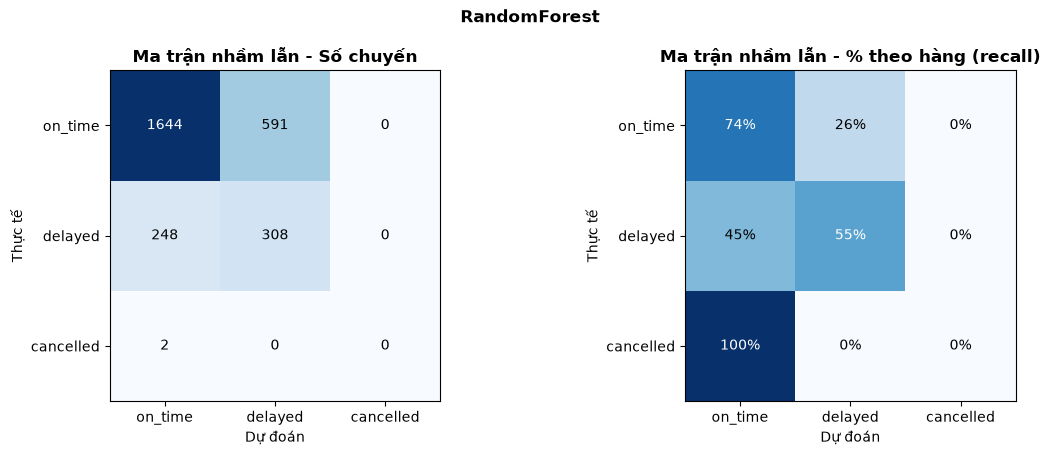

=== Bảng 3: BÁO CÁO THEO TỪNG LỚP ===


,precision,recall,f1-score,support
on_time,0.868,0.736,0.796,2235.0
delayed,0.343,0.554,0.423,556.0
cancelled,0.000,0.000,0.000,2.0
macro avg,0.404,0.430,0.407,2793.0
weighted avg,0.763,0.699,0.722,2793.0


Lưu ý: lớp cancelled chỉ có vài chuyến trong Test, nên precision/recall của lớp này gần như là nhiễu; macro-F1 bị kéo mạnh bởi lớp này.


In [5]:
cm = np.array(clf[best]["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, mat, title, fmt in [(axes[0], cm, "Số chuyến", "{:d}"), (axes[1], cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100, "% theo hàng (recall)", "{:.0f}%")]:
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(f"Ma trận nhầm lẫn - {title}", fontweight="bold")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(int(mat[i, j]) if "d" in fmt else mat[i, j]), ha="center", va="center",
                    color="white" if mat[i, j] > mat.max() * 0.55 else "black")
plt.suptitle(f"{best}", fontweight="bold")
plt.tight_layout()
plt.show()

rep = pd.DataFrame(clf[best]["classification_report"]).T.loc[CLASS_NAMES + ["macro avg", "weighted avg"]].round(3)
print("=== Bảng 3: BÁO CÁO THEO TỪNG LỚP ===")
display(rep)
print("Lưu ý: lớp cancelled chỉ có vài chuyến trong Test, nên precision/recall của lớp này gần như là nhiễu; macro-F1 bị kéo mạnh bởi lớp này.")

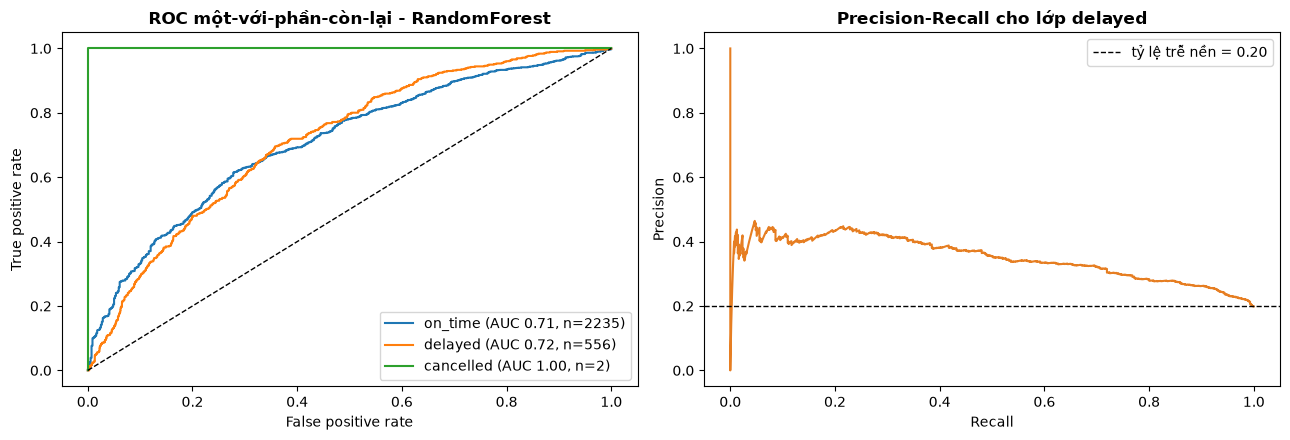

In [6]:
model = joblib.load(tr.FILE_CLASSIFIER)
prob = model.predict_proba(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, name in enumerate(CLASS_NAMES):
    yb = (y_test.values == k)
    if yb.sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(yb, prob[:, k])
    area = sk_auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {area:.2f}, n={int(yb.sum())})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title(f"ROC một-với-phần-còn-lại - {best}", fontweight="bold"); axes[0].legend()

yb = (y_test.values == 1)
pr, rc, _ = precision_recall_curve(yb, prob[:, 1])
axes[1].plot(rc, pr, color="#e67e22")
axes[1].axhline(yb.mean(), color="k", ls="--", lw=1, label=f"tỷ lệ trễ nền = {yb.mean():.2f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
axes[1].set_title("Precision-Recall cho lớp delayed", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.2. Tầm quan trọng đặc trưng
`HistGradientBoosting` **không có** `feature_importances_` (đó là lý do bản trước trả về danh sách rỗng). Vì vậy dùng **permutation importance** trên tập Test: xáo trộn từng cột và đo mức tăng log-loss; tỷ trọng được chuẩn hóa để tổng bằng 100%. Phần dưới cũng gộp các cột One-Hot về biến gốc (`airport_SGN`, `airport_HAN`, ... thành `airport`) để dễ diễn giải.

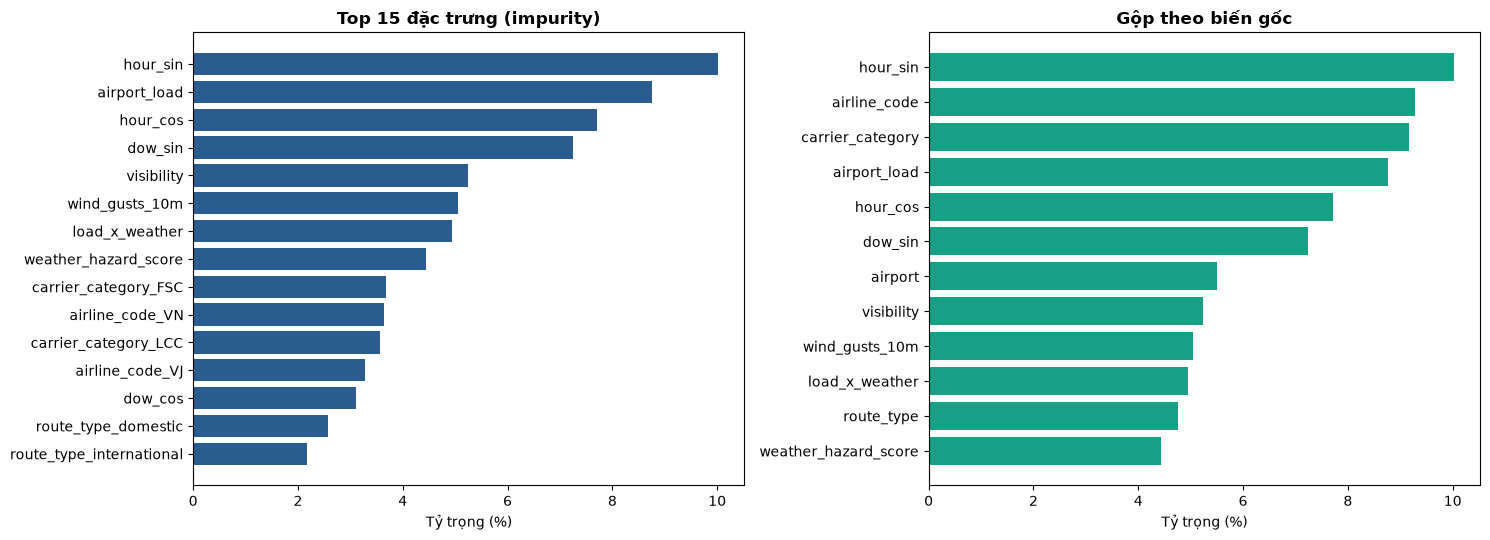

Top 10:
   1. hour_sin                     10.02%
   2. airport_load                  8.76%
   3. hour_cos                      7.71%
   4. dow_sin                       7.24%
   5. visibility                    5.24%
   6. wind_gusts_10m                5.05%
   7. load_x_weather                4.94%
   8. weather_hazard_score          4.44%
   9. carrier_category_FSC          3.68%
  10. airline_code_VN               3.64%

Lưu ý: tầm quan trọng chỉ cho biết đặc trưng nào mô hình DỰA VÀO, không chứng minh quan hệ nhân quả.


In [7]:
fi = pd.DataFrame(metrics["feature_importances"]).head(15)
bv = pd.DataFrame(metrics["feature_importance_by_variable"]).head(12)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(fi["feature"][::-1], fi["importance"][::-1] * 100, color="#2b5c8f")
axes[0].set_title(f"Top 15 đặc trưng ({fi['method'].iloc[0]})", fontweight="bold"); axes[0].set_xlabel("Tỷ trọng (%)")
axes[1].barh(bv["variable"][::-1], bv["importance"][::-1] * 100, color="#16a085")
axes[1].set_title("Gộp theo biến gốc", fontweight="bold"); axes[1].set_xlabel("Tỷ trọng (%)")
plt.tight_layout()
plt.show()
print("Top 10:")
for r, item in enumerate(metrics["feature_importances"][:10], 1):
    print(f"  {r:2d}. {item['feature']:<28} {item['importance'] * 100:5.2f}%")
print("\nLưu ý: tầm quan trọng chỉ cho biết đặc trưng nào mô hình DỰA VÀO, không chứng minh quan hệ nhân quả.")

### 2.3. Xác suất dự báo có đáng tin không? (Calibration)
`class_weight="balanced"` làm mô hình **tăng xác suất** của lớp hiếm. Nếu giao diện web hiển thị xác suất đó như "rủi ro trễ", con số sẽ **cao hơn thực tế**. Biểu đồ so sánh xác suất dự đoán với tần suất trễ thật trong từng nhóm; đường chéo là hiệu chỉnh hoàn hảo.

,bin,n,mean_predicted,observed_rate
0,1,559,0.1769,0.0537
1,2,558,0.2838,0.1093
2,3,559,0.3781,0.1789
3,4,558,0.5025,0.2706
4,5,559,0.6605,0.3828


Brier score (delayed) = 0.1884 | tỷ lệ trễ nền ở Test = 0.1991


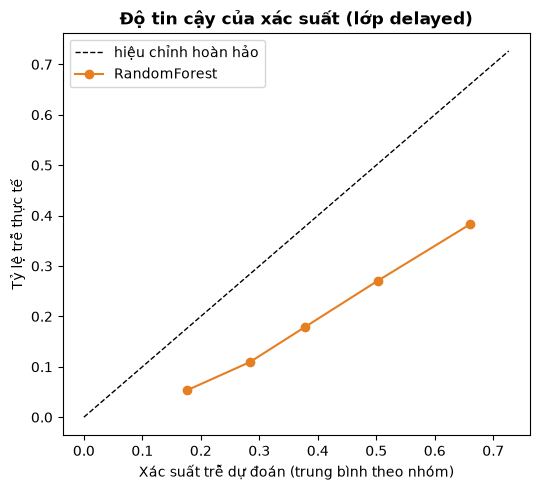

Chênh lệch trung bình (dự đoán - thực tế) = +0.201  -> xác suất đang bị thổi phồng; cần hiệu chỉnh trước khi hiển thị cho người dùng.


In [8]:
cal = metrics["probability_calibration"]
cdf = pd.DataFrame(cal["bins"])
display(cdf)
print(f"Brier score (delayed) = {cal['brier_delayed']} | tỷ lệ trễ nền ở Test = {cal['base_rate_delayed']}")
fig, ax = plt.subplots(figsize=(5.5, 5))
lim = max(cdf["mean_predicted"].max(), cdf["observed_rate"].max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", lw=1, label="hiệu chỉnh hoàn hảo")
ax.plot(cdf["mean_predicted"], cdf["observed_rate"], "o-", color="#e67e22", label=best)
ax.set_xlabel("Xác suất trễ dự đoán (trung bình theo nhóm)"); ax.set_ylabel("Tỷ lệ trễ thực tế")
ax.set_title("Độ tin cậy của xác suất (lớp delayed)", fontweight="bold"); ax.legend()
plt.tight_layout()
plt.show()
gap = float((cdf["mean_predicted"] - cdf["observed_rate"]).mean())
print(f"Chênh lệch trung bình (dự đoán - thực tế) = {gap:+.3f}" + ("  -> xác suất đang bị thổi phồng; cần hiệu chỉnh trước khi hiển thị cho người dùng." if gap > 0.05 else ""))

### 2.4. Hồi quy số phút trễ
Mô hình hồi quy dự báo `delay_min` trên các chuyến có số phút trễ (chuyến hủy không có). Ba ứng viên (HistGradientBoosting bình phương sai số, HistGradientBoosting sai số tuyệt đối, RandomForest) được chọn bằng MAE qua `TimeSeriesSplit` trên Train, rồi so với **baseline luôn đoán trung vị**. Nếu mô hình chỉ hơn baseline vài phần trăm, nghĩa là số phút trễ **gần như không dự báo được** từ các đặc trưng hiện có.

Mô hình được chọn: HistGradientBoosting_MAE (n_train = 11,045, n_test = 2,790)


,MAE (phút),RMSE (phút),R2
Mô hình,15.13,30.28,0.069
Baseline (đoán trung vị),15.43,NaN,NaN


MAE cải thiện so với baseline: 1.9% | trễ trung bình ở Test: 8.37 phút


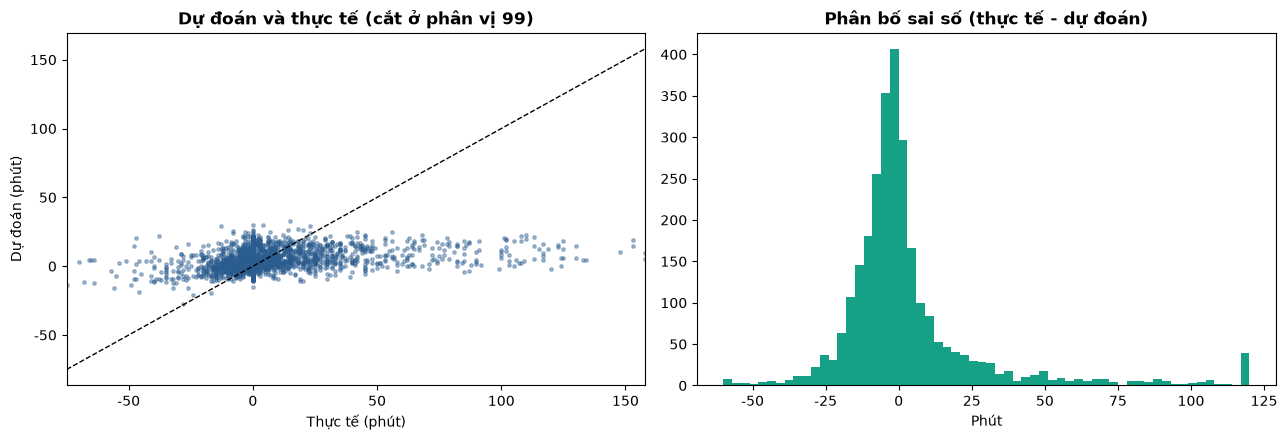

In [9]:
reg, det = metrics["regression"], metrics["regression_details"]
print(f"Mô hình được chọn: {det['selected']} (n_train = {det['n_train']:,}, n_test = {det['n_test']:,})")
display(pd.DataFrame({"MAE (phút)": [reg["MAE_minutes"], det["baseline_median_MAE_minutes"]],
                      "RMSE (phút)": [reg["RMSE_minutes"], np.nan], "R2": [reg["R2_Score"], np.nan]},
                     index=["Mô hình", "Baseline (đoán trung vị)"]))
print(f"MAE cải thiện so với baseline: {det['mae_improvement_vs_baseline_pct']}% | trễ trung bình ở Test: {det['test_delay_mean_minutes']} phút")

rg = joblib.load(tr.FILE_REGRESSOR)
mask = delay_test.notna().values
pred = rg.predict(X_test[mask]); act = delay_test[mask].values
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(act, pred, s=6, alpha=0.4, color="#2b5c8f")
lim = np.percentile(act, 99)
axes[0].plot([act.min(), lim], [act.min(), lim], "k--", lw=1)
axes[0].set_xlim(act.min(), lim); axes[0].set_xlabel("Thực tế (phút)"); axes[0].set_ylabel("Dự đoán (phút)")
axes[0].set_title("Dự đoán và thực tế (cắt ở phân vị 99)", fontweight="bold")
axes[1].hist(np.clip(act - pred, -60, 120), bins=60, color="#16a085")
axes[1].set_title("Phân bố sai số (thực tế - dự đoán)", fontweight="bold"); axes[1].set_xlabel("Phút")
plt.tight_layout()
plt.show()

## 3. Học không giám sát (Unsupervised Learning)
Cả ba mô hình **fit trên Train**; hồ sơ cụm và cờ bất thường được áp lên cả Train và Test để kiểm tra độ ổn định.

### 3.1. K-Means
- **Chọn k:** quét k = 2..8 (inertia cho phương pháp khuỷu tay, silhouette cho độ tách cụm). Dự án dùng k = 4 vì mục đích vận hành; nếu silhouette tốt nhất ở k khác thì cần nêu rõ lý do chọn k = 4.
- **Đặt tên cụm từ dữ liệu:** số thứ tự cụm của K-Means là ngẫu nhiên nên **không thể gán tên cố định theo số thứ tự**. Tên cụm được suy ra từ giờ bay trung bình (trung bình vòng tròn của `hour_sin`/`hour_cos` sau khi đưa về thang gốc) và điều kiện thời tiết trung bình của cụm.

In [10]:
summary = un.run_unsupervised_pipeline()
km = summary["kmeans"]


      K-MEANS (k=4) - FIT TRÊN TRAIN
  k  | inertia    | silhouette
  2  |   142978.0 | 0.2060  <- tốt nhất
  3  |   131218.3 | 0.0976
  4  |   121376.0 | 0.0985
  5  |   114630.2 | 0.1006
  6  |   108002.6 | 0.1056
  7  |   103731.3 | 0.1075
  8  |   100003.7 | 0.1002

  k đang dùng = 4: silhouette 0.0985 | inertia 121376.0  (k tốt nhất theo silhouette: 2)

* Cụm 0: Morning, Clear weather (Buổi sáng, Thời tiết tốt)
    - Quy mô 5,833 chuyến (41.8%) | trễ 23.9% (Train 26.0% / Test 14.2%) | hủy 0.86% | rủi ro MEDIUM

* Cụm 1: Afternoon, Windy/Reduced visibility (Buổi chiều, Gió mạnh/tầm nhìn giảm)
    - Quy mô 3,070 chuyến (22.0%) | trễ 30.4% (Train 34.6% / Test 17.4%) | hủy 1.21% | rủi ro HIGH

* Cụm 2: Evening, Clear weather (Buổi tối, Thời tiết tốt)
    - Quy mô 4,816 chuyến (34.5%) | trễ 30.3% (Train 31.0% / Test 27.8%) | hủy 0.58% | rủi ro HIGH

* Cụm 3: Afternoon, Rain/Storm (Buổi chiều, Mưa lớn/dông)
    - Quy mô 246 chuyến (1.8%) | trễ 39.0% (Train 41.6% / Test 0.0%) | hủy 1.63

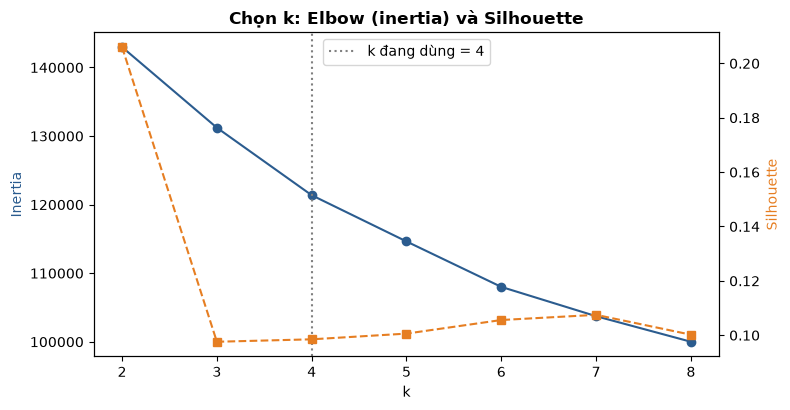

,k,inertia,silhouette
0,2,142978.0,0.2060
1,3,131218.3,0.0976
2,4,121376.0,0.0985
3,5,114630.2,0.1006
4,6,108002.6,0.1056
5,7,103731.3,0.1075
6,8,100003.7,0.1002


k tốt nhất theo silhouette = 2 | silhouette ở k = 4: 0.0985
Lưu ý: silhouette ở k = 4 thấp (cụm chồng lấn). Cụm ở đây là PHÂN NHÓM THAM KHẢO, không phải các nhóm tách biệt rõ.


In [11]:
sw = pd.DataFrame(km["k_selection"])
fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.plot(sw["k"], sw["inertia"], "o-", color="#2b5c8f"); ax1.set_xlabel("k"); ax1.set_ylabel("Inertia", color="#2b5c8f")
ax2 = ax1.twinx()
ax2.plot(sw["k"], sw["silhouette"], "s--", color="#e67e22"); ax2.set_ylabel("Silhouette", color="#e67e22")
ax1.axvline(4, color="gray", ls=":", label="k đang dùng = 4")
ax1.set_title("Chọn k: Elbow (inertia) và Silhouette", fontweight="bold"); ax1.legend(loc="upper center")
plt.tight_layout()
plt.show()
display(sw)
print(f"k tốt nhất theo silhouette = {km['best_k_by_silhouette']} | silhouette ở k = 4: {km['silhouette']}")
if km["best_k_by_silhouette"] != 4 or (km["silhouette"] or 0) < 0.25:
    print("Lưu ý: silhouette ở k = 4 thấp (cụm chồng lấn). Cụm ở đây là PHÂN NHÓM THAM KHẢO, không phải các nhóm tách biệt rõ.")

In [12]:
prof = pd.DataFrame(km["profiles"]).T
cols = [c for c in ["name", "flight_count", "percentage", "mean_hour", "avg_precipitation_mm", "avg_wind_gust_kmh", "avg_visibility_km",
                    "avg_airport_load", "dominant_airline", "dominant_airport", "domestic_pct"] if c in prof.columns]
print("=== Bảng 4: HỒ SƠ 4 CỤM (tên suy ra từ dữ liệu) ===")
display(prof[cols])
print("=== Bảng 5: RỦI RO VÀ ĐỘ ỔN ĐỊNH GIỮA TRAIN VÀ TEST ===")
stab = prof[["name", "delay_rate_pct", "train_delay_rate_pct", "test_delay_rate_pct", "cancellation_rate_pct", "avg_delay_minutes", "risk_tier"]].copy()
stab["lệch Test-Train (điểm %)"] = (stab["test_delay_rate_pct"].astype(float) - stab["train_delay_rate_pct"].astype(float)).round(1)
display(stab)
print("Cụm ổn định nếu tỷ lệ trễ ở Test gần với Train; chênh lệch lớn (đặc biệt ở cụm nhỏ) cho thấy hồ sơ rủi ro của cụm chưa vững.")

=== Bảng 4: HỒ SƠ 4 CỤM (tên suy ra từ dữ liệu) ===


,name,flight_count,percentage,mean_hour,avg_precipitation_mm,avg_wind_gust_kmh,avg_visibility_km,avg_airport_load,dominant_airline,dominant_airport,domestic_pct
0,"Morning, Clear weather (Buổi sáng, Thời tiết tốt)",5833,41.8,11.6,0.04,19.8,17.1,28.3,VN,SGN,73.2
1,"Afternoon, Windy/Reduced visibility (Buổi chiề...",3070,22.0,14.5,0.63,24.8,6.3,26.2,VN,SGN,72.5
2,"Evening, Clear weather (Buổi tối, Thời tiết tốt)",4816,34.5,20.8,0.05,13.3,14.2,23.7,VN,HAN,61.3
3,"Afternoon, Rain/Storm (Buổi chiều, Mưa lớn/dông)",246,1.8,13.8,4.9,30.2,4.1,25.4,VN,SGN,73.6


=== Bảng 5: RỦI RO VÀ ĐỘ ỔN ĐỊNH GIỮA TRAIN VÀ TEST ===


,name,delay_rate_pct,train_delay_rate_pct,test_delay_rate_pct,cancellation_rate_pct,avg_delay_minutes,risk_tier,lệch Test-Train (điểm %)
0,"Morning, Clear weather (Buổi sáng, Thời tiết tốt)",23.9,26.0,14.2,0.86,9.2,MEDIUM,-11.8
1,"Afternoon, Windy/Reduced visibility (Buổi chiề...",30.4,34.6,17.4,1.21,12.1,HIGH,-17.2
2,"Evening, Clear weather (Buổi tối, Thời tiết tốt)",30.3,31.0,27.8,0.58,12.1,HIGH,-3.2
3,"Afternoon, Rain/Storm (Buổi chiều, Mưa lớn/dông)",39.0,41.6,0.0,1.63,15.1,HIGH,-41.6


Cụm ổn định nếu tỷ lệ trễ ở Test gần với Train; chênh lệch lớn (đặc biệt ở cụm nhỏ) cho thấy hồ sơ rủi ro của cụm chưa vững.


### 3.2. PCA
PCA (fit trên Train) chiếu không gian đặc trưng xuống 2-3 chiều để trực quan hóa. Do có nhiều cột One-Hot, phương sai tích lũy của vài thành phần đầu thường thấp, nên biểu đồ chỉ mang tính minh họa.

Phương sai giải thích: PC1 22.96%, PC2 11.0% (tổng 2D 34.0%)


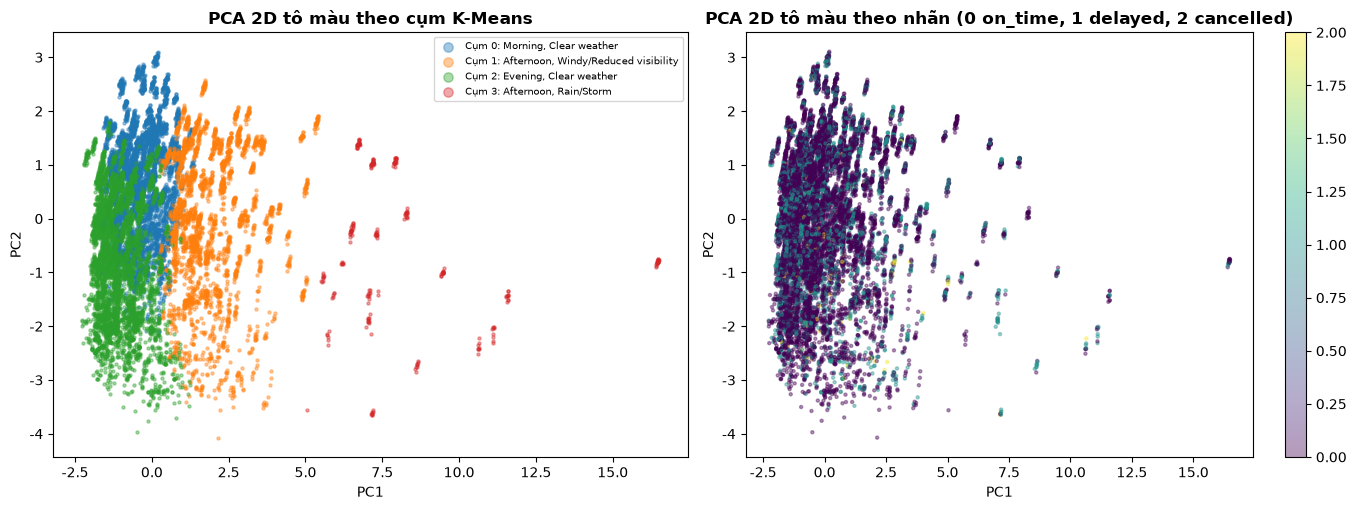

PC1: weather_hazard_score (+0.53), load_x_weather (+0.49), precipitation (+0.45), wind_gusts_10m (+0.34), visibility (-0.28)
PC2: airport_load (+0.61), hour_cos (-0.43), visibility (+0.34), wind_gusts_10m (+0.32), is_heavy_traffic (+0.28)


In [13]:
X_tr, X_te, tr_df, te_df = un.load_train_test_matrices()
Xall = pd.concat([X_tr, X_te], ignore_index=True)
dfall = pd.concat([tr_df, te_df], ignore_index=True)
pca = joblib.load(un.FILE_PCA); kmeans = joblib.load(un.FILE_KMEANS)
Z = pca.transform(Xall); lab = kmeans.predict(Xall)
pm = summary["pca"]
print(f"Phương sai giải thích: PC1 {pm['explained_variance_ratios'][0]}%, PC2 {pm['explained_variance_ratios'][1]}% (tổng 2D {pm['cumulative_variance_2d'] * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for cid in range(4):
    m = lab == cid
    axes[0].scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.4, label=f"Cụm {cid}: {km['profiles'][str(cid)]['name'].split(' (')[0]}")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title("PCA 2D tô màu theo cụm K-Means", fontweight="bold"); axes[0].legend(fontsize=7, markerscale=3)
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=(dfall["target"].values), s=5, alpha=0.4, cmap="viridis")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("PCA 2D tô màu theo nhãn (0 on_time, 1 delayed, 2 cancelled)", fontweight="bold")
plt.colorbar(sc, ax=axes[1])
plt.tight_layout()
plt.show()
for pc, lst in pm["top_loadings"].items():
    print(f"{pc}: " + ", ".join(f"{r['feature']} ({r['loading']:+.2f})" for r in lst))

### 3.3. Isolation Forest (phát hiện bất thường)
**Lưu ý quan trọng khi diễn giải:** `contamination = 3%` là **tham số do người dùng đặt**, nên tỷ lệ ≈ 3% trên Train luôn đúng theo cách xây dựng, **không phải một phát hiện**. Phần có giá trị là: (a) tỷ lệ bị gắn cờ trên **Test** (nếu cao hơn nhiều, dữ liệu mới khác dữ liệu huấn luyện) và (b) các chuyến bị gắn cờ **khác bình thường ở đặc trưng nào** và có tỷ lệ trễ/hủy ra sao.

Gắn cờ: 392 chuyến (2.81% tổng) | Train 3.01% (do contamination) | Test 2.01%


,Tỷ lệ trễ (%),Tỷ lệ hủy (%)
Bị gắn cờ bất thường,32.1,2.30
Bình thường,27.7,0.81


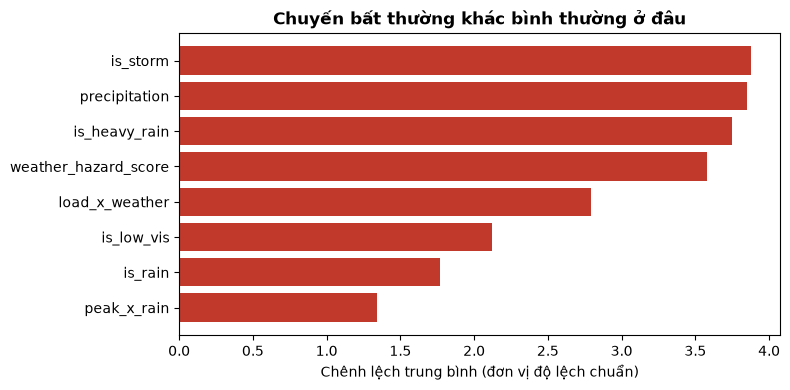

Số chuyến bị gắn cờ theo cụm: {'0': 2, '1': 171, '2': 21, '3': 198}


In [14]:
iso = summary["isolation_forest"]
print(f"Gắn cờ: {iso['anomaly_count']:,} chuyến ({iso['anomaly_percentage']}% tổng) | Train {iso['train_flagged_pct']}% (do contamination) | Test {iso['test_flagged_pct']}%")
display(pd.DataFrame({"Tỷ lệ trễ (%)": [iso.get("delay_rate_flagged_pct"), iso.get("delay_rate_normal_pct")],
                      "Tỷ lệ hủy (%)": [iso.get("cancel_rate_flagged_pct"), iso.get("cancel_rate_normal_pct")]},
                     index=["Bị gắn cờ bất thường", "Bình thường"]))
td = pd.DataFrame(iso["top_distinguishing_features"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(td["feature"][::-1], td["std_diff"][::-1], color="#c0392b")
ax.set_xlabel("Chênh lệch trung bình (đơn vị độ lệch chuẩn)")
ax.set_title("Chuyến bất thường khác bình thường ở đâu", fontweight="bold")
plt.tight_layout()
plt.show()
if iso.get("flagged_by_cluster"):
    print("Số chuyến bị gắn cờ theo cụm:", iso["flagged_by_cluster"])

### 3.4. Luật kết hợp (FP-Growth)
Top luật **theo lift giảm dần** từ `data/mined_association_rules.csv` (do bước `python main.py process` sinh ra). Lift > 1 nghĩa là vế trái làm tăng khả năng của vế phải so với nền; cần xem cả support để loại luật quá hiếm.

In [15]:
rules = pd.DataFrame(summary["association_rules"])
if rules.empty:
    print("Chưa có data/mined_association_rules.csv. Chạy: python main.py process")
else:
    print(f"Top {len(rules)} luật theo lift:")
    display(rules)

Top 15 luật theo lift:


,Antecedent,Consequent,Count,Support (%),Confidence (%),Lift,Leverage,Conviction
0,Airline=VN & Load=low & Route=domestic,Status=cancelled,53,0.39,4.72,6.74,0.0033,1.04
1,Airline=VN & Day=weekday & Load=low,Status=cancelled,51,0.38,3.88,5.54,0.0031,1.03
2,Airline=VN & Day=weekday & Route=domestic,Status=cancelled,76,0.56,3.49,4.98,0.0045,1.03
3,Airline=VJ & Rain=light & Slot=18h-24h,Status=delayed,145,1.07,52.35,1.99,0.0053,1.55
4,Airline=VJ & Airport=SGN & Slot=18h-24h,Status=delayed,281,2.07,51.94,1.97,0.0102,1.53
5,Airline=VJ & Airport=SGN & Slot=12h-18h,Status=delayed,422,3.11,50.60,1.92,0.0149,1.49
6,Airline=VJ & Airport=SGN & Rain=light,Status=delayed,457,3.37,50.39,1.91,0.0161,1.49
7,Airline=VJ & Route=domestic & Slot=18h-24h,Status=delayed,446,3.29,49.45,1.88,0.0154,1.46
8,Airline=VJ & Load=low & Slot=18h-24h,Status=delayed,221,1.63,48.68,1.85,0.0075,1.44
9,Airport=SGN & Load=low & Slot=18h-24h,Status=delayed,250,1.84,47.80,1.82,0.0083,1.41


## 4. Tổng kết, hạn chế và nội dung cho báo cáo
Ô dưới in **kết luận tự động từ số liệu vừa tính**, kèm các cảnh báo cần nêu trong báo cáo.

In [16]:
n_canc = int((y_test == 2).sum())
print("KẾT LUẬN TỰ ĐỘNG")
print(f"1. Mô hình phân loại được chọn: {best} (chọn bằng TimeSeriesSplit trên Train). Macro-F1 Test {clf[best]['f1_macro']:.3f} so với baseline {base['f1_macro']:.3f}; "
      f"ROC-AUC {clf[best]['roc_auc_ovr']}.")
better = clf[best]["f1_macro"] > base["f1_macro"]
print(f"   -> {'Mô hình học được tín hiệu hơn baseline, nhưng' if better else 'Mô hình KHÔNG hơn baseline; '}" +
      f" Accuracy ({clf[best]['accuracy']:.3f}) vẫn {'thấp hơn' if clf[best]['accuracy'] < base['accuracy'] else 'cao hơn'} baseline ({base['accuracy']:.3f}).")
print(f"2. Lớp cancelled: chỉ {n_canc} chuyến trong Test; recall = {clf[best]['classification_report']['cancelled']['recall']:.2f}. Không nên kết luận về khả năng dự báo hủy chuyến.")
print(f"3. Hồi quy số phút trễ: MAE {reg['MAE_minutes']} phút, R2 = {reg['R2_Score']}; chỉ cải thiện {det['mae_improvement_vs_baseline_pct']}% MAE so với đoán trung vị.")
print(f"4. K-Means: silhouette ở k = 4 là {km['silhouette']} (k tốt nhất theo silhouette: {km['best_k_by_silhouette']}); đây là phân nhóm tham khảo.")
print(f"5. Isolation Forest: tỷ lệ gắn cờ 3% trên Train do tham số; trên Test là {iso['test_flagged_pct']}%.")
print("\nCẢNH BÁO TỪ HỆ THỐNG:")
for n in metrics["notes"]:
    print(" -", n)

KẾT LUẬN TỰ ĐỘNG
1. Mô hình phân loại được chọn: RandomForest (chọn bằng TimeSeriesSplit trên Train). Macro-F1 Test 0.407 so với baseline 0.296; ROC-AUC 0.8086.
   -> Mô hình học được tín hiệu hơn baseline, nhưng Accuracy (0.699) vẫn thấp hơn baseline (0.800).
2. Lớp cancelled: chỉ 2 chuyến trong Test; recall = 0.00. Không nên kết luận về khả năng dự báo hủy chuyến.
3. Hồi quy số phút trễ: MAE 15.13 phút, R2 = 0.069; chỉ cải thiện 1.9% MAE so với đoán trung vị.
4. K-Means: silhouette ở k = 4 là 0.0985 (k tốt nhất theo silhouette: 2); đây là phân nhóm tham khảo.
5. Isolation Forest: tỷ lệ gắn cờ 3% trên Train do tham số; trên Test là 2.01%.

CẢNH BÁO TỪ HỆ THỐNG:
 - Tập Test chỉ có 2 chuyến hủy: chỉ số của lớp cancelled (và macro-F1) có độ bất định rất lớn; đừng so sánh mô hình dựa trên chênh lệch nhỏ của macro-F1.
 - Tỷ lệ trễ ở Train và Test khác nhau rõ rệt (lệch phân phối theo thời gian); xác suất dự báo sẽ lệch theo.
 - class_weight='balanced' làm xác suất dự báo cao hơn thực tế ch

**Hạn chế cần nêu trong báo cáo**
1. **Lệch phân phối theo thời gian:** tỷ lệ trễ ở giai đoạn đầu và giai đoạn sau khác nhau; mô hình huấn luyện trên giai đoạn cũ dự báo giai đoạn mới với độ chính xác thấp hơn.
2. **Lớp cancelled rất hiếm** nên không đánh giá được tin cậy; macro-F1 nhạy với lớp này.
3. **Xác suất bị thổi phồng** do `class_weight="balanced"`; muốn dùng làm điểm rủi ro cho người dùng cần hiệu chỉnh (calibration) hoặc ghi rõ đây là điểm xếp hạng, không phải xác suất.
4. **Mẫu lệch về chuyến hủy** do bộ lọc API (`--status cancelled,landed`), nên tỷ lệ trong mẫu không so trực tiếp với thống kê chính thức.
5. **Quan hệ nhân quả:** tầm quan trọng đặc trưng và luật kết hợp chỉ cho thấy sự đi kèm, không chứng minh nguyên nhân.
6. **Ghim phiên bản scikit-learn:** các tệp `.joblib` gắn với phiên bản đã tạo ra chúng; cả nhóm (đặc biệt Thành viên 6 chạy web) phải cài cùng phiên bản.

**Bàn giao:** Thành viên 6 dùng `models/best_classifier.joblib`, `best_regressor.joblib`, `kmeans_model.joblib`, `cluster_profiles.json` và các artifact của Thành viên 4; Thành viên 8 đọc `supervised_metrics.json` và `unsupervised_metrics.json`.